**OBD - Réplica de resultados**

Evaluaremos estimadores OPE. Para ello, usaremos los datos de la política Bernoulli Thompson Sampling (BTS) para estimar el CTR de la política Random, y lo compararemos con su CTR real (Random también fue probada en producción en ZOZOTOWN).

El objetivo del presente documento es replicar los experimentos realizados en Saito et al. (2021)(paper asociado a OBD), con miras a extender esta evaluación a KuaiRand (ver KuaiRand-obp.ipynb).


Primero cargamos el dataset y obtenemos los resultados de random registrados en aquel.

In [2]:
from pathlib import Path
from obp.dataset import OpenBanditDataset

OBD_PATH = Path("Contenido/Datasets/open_bandit_dataset/open_bandit_dataset")
CAMPAIGN = "men"

datos_bts = OpenBanditDataset(behavior_policy="bts", campaign=CAMPAIGN, data_path=OBD_PATH)
datos_random = OpenBanditDataset(behavior_policy="random", campaign=CAMPAIGN, data_path=OBD_PATH)

ctr_real_random = datos_random.reward.mean()
print(f"BTS: {datos_bts.n_rounds:,} filas | Random: {datos_random.n_rounds:,} filas")
print(f"CTR real de Random: {ctr_real_random:.5f}")

BTS: 4,077,727 filas | Random: 452,949 filas
CTR real de Random: 0.00512


Se tiene una media de 0.00512 de CTR obtenido por Random.

Revisamos las probabilidades de cada ítem (uniforme)

In [4]:
from obp.policy import Random
politica_random = Random(n_actions=datos_bts.n_actions, len_list=datos_bts.len_list, random_state=12345)
pi_e = politica_random.compute_batch_action_dist(n_rounds=1)

print("Forma:", pi_e.shape)  # (rondas, ítems, posiciones)
print("Probabilidades del ítem 0 en las 3 posiciones:", pi_e[0, 0])
print("1/34 =", 1 / 34)

Forma: (1, 34, 3)
Probabilidades del ítem 0 en las 3 posiciones: [0.02941176 0.02941176 0.02941176]
1/34 = 0.029411764705882353


Ahora veamos una muestra de bts, utilizando una primera semilla (0).

In [ ]:
import numpy as np

N = 10_000  
feedback_bts = datos_bts.obtain_batch_bandit_feedback()

np.random.seed(0) 
idx = np.random.choice(feedback_bts["n_rounds"], size=N, replace=True)  

muestra = {k: v[idx] if isinstance(v, np.ndarray) and len(v) == feedback_bts["n_rounds"] else v
           for k, v in feedback_bts.items()}
muestra["n_rounds"] = N
pi_e_muestra = politica_random.compute_batch_action_dist(n_rounds=N)

print("Filas en la muestra:", muestra["n_rounds"])
print("CTR de BTS en la muestra:", muestra["reward"].mean())
print("Forma de pi_e:", pi_e_muestra.shape)

Filas en la muestra: 10000
CTR de BTS en la muestra: 0.0064
Forma de pi_e: (10000, 34, 3)


Instanciamos los estimadores por evaluar, junto con la metodología utilizada (Gradient Boosting), veamos sus resultados.

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier
from obp.ope import (OffPolicyEvaluation, RegressionModel, DirectMethod, InverseProbabilityWeighting,
                     SelfNormalizedInverseProbabilityWeighting, DoublyRobust, SelfNormalizedDoublyRobust,
                     SwitchDoublyRobustTuning, DoublyRobustWithShrinkageTuning)

SEMILLA = 0
LAMBDAS = [1, 5, 10, 50, 100, 500, 1000, 5000, 10000]
TUNING = dict(lambdas=LAMBDAS, tuning_method="mse", delta=0.05)

estimadores = [
    InverseProbabilityWeighting(estimator_name="IPW"),
    SelfNormalizedInverseProbabilityWeighting(estimator_name="SNIPW"),
    DirectMethod(estimator_name="DM"),
    DoublyRobust(estimator_name="DR"),
    SelfNormalizedDoublyRobust(estimator_name="SNDR"),
    SwitchDoublyRobustTuning(**TUNING, estimator_name="Switch-DR"),
    DoublyRobustWithShrinkageTuning(**TUNING, estimator_name="DRos"),
]

modelo_q = RegressionModel(
    n_actions=muestra["n_actions"], len_list=datos_bts.len_list, fitting_method="normal",
    base_model=HistGradientBoostingClassifier(learning_rate=0.01, max_iter=100, max_depth=5,
                                              min_samples_leaf=10, random_state=SEMILLA))
q_hat = modelo_q.fit_predict(context=muestra["context"], action=muestra["action"], reward=muestra["reward"],
                             position=muestra["position"], pscore=muestra["pscore"],
                             n_folds=2, random_state=SEMILLA)

ope = OffPolicyEvaluation(bandit_feedback=muestra, ope_estimators=estimadores)
estimaciones = ope.estimate_policy_values(action_dist=pi_e_muestra, estimated_rewards_by_reg_model=q_hat)

for nombre, v in estimaciones.items():
    print(f"{nombre:10s} estimado = {v:.5f} | real = {ctr_real_random:.5f} | error² = {(v - ctr_real_random)**2:.2e}")

IPW        estimado = 0.00465 | real = 0.00512 | error² = 2.21e-07
SNIPW      estimado = 0.00521 | real = 0.00512 | error² = 6.94e-09
DM         estimado = 0.00529 | real = 0.00512 | error² = 2.75e-08
DR         estimado = 0.00533 | real = 0.00512 | error² = 4.08e-08
SNDR       estimado = 0.00533 | real = 0.00512 | error² = 4.26e-08
Switch-DR  estimado = 0.00536 | real = 0.00512 | error² = 5.43e-08
DRos       estimado = 0.00526 | real = 0.00512 | error² = 1.75e-08


Ahora se realiza el experimento con 200 semillas (T = 200, como en paper base), para posteriormente guardar los resultados. Se utiliza la ponderación por 1000 al final, de forma similar a como están reportados los resultados en el paper base.

In [ ]:
import time
import pandas as pd

N_SEMILLAS = 200 


def iteracion(semilla, n):

    np.random.seed(semilla)
    idx = np.random.choice(feedback_bts["n_rounds"], size=n, replace=True)
    muestra = {k: v[idx] if isinstance(v, np.ndarray) and len(v) == feedback_bts["n_rounds"] else v
               for k, v in feedback_bts.items()}
    muestra["n_rounds"] = n

    modelo_q = RegressionModel(
        n_actions=muestra["n_actions"], len_list=datos_bts.len_list, fitting_method="normal",
        base_model=HistGradientBoostingClassifier(learning_rate=0.01, max_iter=100, max_depth=5,
                                                  min_samples_leaf=10, random_state=semilla))
    q_hat = modelo_q.fit_predict(context=muestra["context"], action=muestra["action"], reward=muestra["reward"],
                                 position=muestra["position"], pscore=muestra["pscore"],
                                 n_folds=2, random_state=semilla)
    ope = OffPolicyEvaluation(bandit_feedback=muestra, ope_estimators=estimadores)
    return ope.estimate_policy_values(action_dist=politica_random.compute_batch_action_dist(n_rounds=n),
                                      estimated_rewards_by_reg_model=q_hat)


inicio = time.time()
filas = []
for semilla in range(N_SEMILLAS):
    for nombre, v in iteracion(semilla, N).items():
        filas.append({"semilla": semilla, "estimador": nombre, "estimado": v})
    if (semilla + 1) % 20 == 0:
        print(f"{semilla + 1}/{N_SEMILLAS} semillas | {(time.time() - inicio) / 60:.1f} min")

resultados = pd.DataFrame(filas)
resultados["error2"] = (resultados["estimado"] - ctr_real_random) ** 2
Path("resultados").mkdir(exist_ok=True)
resultados.to_csv("resultados/ope_men_n10000.csv", index=False)

rmse = resultados.groupby("estimador")["error2"].mean().pow(0.5).sort_values()
(rmse * 1000).round(3) 

20/200 semillas | 7.8 min
40/200 semillas | 17.1 min
60/200 semillas | 24.8 min
80/200 semillas | 31.4 min
100/200 semillas | 38.0 min
120/200 semillas | 44.5 min
140/200 semillas | 51.1 min
160/200 semillas | 57.8 min
180/200 semillas | 64.2 min
200/200 semillas | 70.8 min


estimador
DRos         1.467
Switch-DR    1.507
DM           1.531
IPW          2.602
SNIPW        2.676
SNDR         2.680
DR           4.015
Name: error2, dtype: float64

Se obtienen diferencias con respecto al paper, en particular en DRos y Switch-DR. Esto se debe a la elección fija de $\lambda$ la primera vez que se usa el estimador y su reutilización en las siguientes 200 semillas. Luego, un $\lambda$ bajo produce que estos estimadores se parezcan más a DM y menos a IPW. Se corrige creando los estimadores de nuevo en cada iteración.

In [ ]:
for est in estimadores[5:]:  
    print(est.estimator_name, "| lambda elegido:", est.best_hyperparam)

Switch-DR | λ elegido: 1
DRos | λ elegido: 1


Se coincide con un lambda bajo. Procedemos a utilizar una función para crear estimadores que se llame en cada iteración.

In [9]:
def crear_estimadores():
    return [
        InverseProbabilityWeighting(estimator_name="IPW"),
        SelfNormalizedInverseProbabilityWeighting(estimator_name="SNIPW"),
        DirectMethod(estimator_name="DM"),
        DoublyRobust(estimator_name="DR"),
        SelfNormalizedDoublyRobust(estimator_name="SNDR"),
        SwitchDoublyRobustTuning(**TUNING, estimator_name="Switch-DR"),
        DoublyRobustWithShrinkageTuning(**TUNING, estimator_name="DRos"),
    ]

Ahora se redefine iteración.

In [ ]:
def iteracion_v2(semilla, n):

    np.random.seed(semilla)
    idx = np.random.choice(feedback_bts["n_rounds"], size=n, replace=True)
    muestra = {k: v[idx] if isinstance(v, np.ndarray) and len(v) == feedback_bts["n_rounds"] else v
               for k, v in feedback_bts.items()}
    muestra["n_rounds"] = n

    modelo_q = RegressionModel(
        n_actions=muestra["n_actions"], len_list=datos_bts.len_list, fitting_method="normal",
        base_model=HistGradientBoostingClassifier(learning_rate=0.01, max_iter=100, max_depth=5,
                                                  min_samples_leaf=10, random_state=semilla))
    q_hat = modelo_q.fit_predict(context=muestra["context"], action=muestra["action"], reward=muestra["reward"],
                                 position=muestra["position"], pscore=muestra["pscore"],
                                 n_folds=2, random_state=semilla)
    ope = OffPolicyEvaluation(bandit_feedback=muestra, ope_estimators=crear_estimadores())
    return ope.estimate_policy_values(action_dist=politica_random.compute_batch_action_dist(n_rounds=n),
                                      estimated_rewards_by_reg_model=q_hat)


Se vuelve a correr el algoritmo, con la modificación incluida. Recordemos que se utiliza la ponderación por 1000 al final, de forma similar a como están reportados los resultados en el paper base.

In [ ]:

inicio = time.time()
filas = []
for semilla in range(N_SEMILLAS):
    for nombre, v in iteracion_v2(semilla, N).items():
        filas.append({"semilla": semilla, "estimador": nombre, "estimado": v})
    if (semilla + 1) % 20 == 0:
        print(f"{semilla + 1}/{N_SEMILLAS} semillas | {(time.time() - inicio) / 60:.1f} min")

resultados = pd.DataFrame(filas)
resultados["error2"] = (resultados["estimado"] - ctr_real_random) ** 2
Path("resultados").mkdir(exist_ok=True)
resultados.to_csv("resultados/ope_men_n10000_tuning_por_semilla.csv", index=False)

rmse = resultados.groupby("estimador")["error2"].mean().pow(0.5).sort_values()
(rmse * 1000).round(3) 

20/200 semillas | 13.1 min
40/200 semillas | 24.6 min
60/200 semillas | 33.9 min
80/200 semillas | 46.3 min
100/200 semillas | 56.1 min
120/200 semillas | 64.7 min
140/200 semillas | 67.7 min
160/200 semillas | 71.0 min
180/200 semillas | 74.4 min
200/200 semillas | 78.1 min


estimador
DM           1.531
DRos         2.071
Switch-DR    2.598
IPW          2.602
SNIPW        2.676
SNDR         2.680
DR           4.015
Name: error2, dtype: float64

Queda propuesto para la siguiente iteración probar los estimadores con un n mayor.
Ahora veamos los gráficos asociados a los resultados obtenidos.

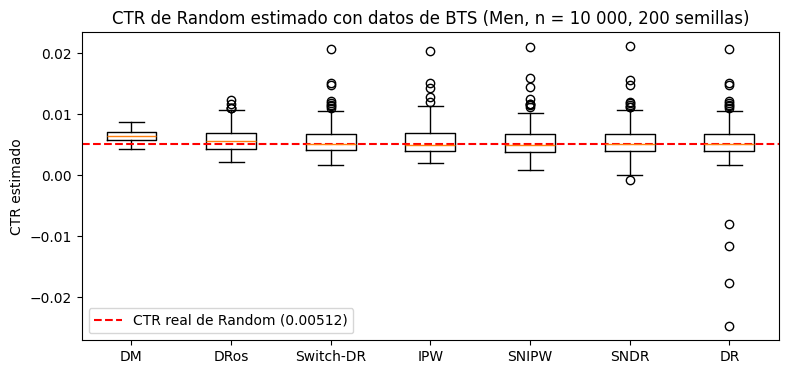

estimador,DM,DRos,Switch-DR,IPW,SNIPW,SNDR,DR
estimador,,,,,,,
DM,NaN,0.949,0.161,0.034,0.022,0.052,0.043
DRos,0.949,NaN,0.262,0.076,0.057,0.103,0.087
Switch-DR,0.161,0.262,NaN,0.560,0.443,0.637,0.550
IPW,0.034,0.076,0.560,NaN,0.853,0.926,0.973
SNIPW,0.022,0.057,0.443,0.853,NaN,0.778,0.879
SNDR,0.052,0.103,0.637,0.926,0.778,NaN,0.890
DR,0.043,0.087,0.550,0.973,0.879,0.890,NaN


In [ ]:
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.stats import mannwhitneyu

res = pd.read_csv("resultados/ope_men_n10000_tuning_por_semilla.csv")
orden = res.groupby("estimador")["error2"].mean().sort_values().index  

# Boxplot
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([res.loc[res["estimador"] == e, "estimado"] for e in orden], labels=orden)
ax.axhline(ctr_real_random, color="red", linestyle="--", label=f"CTR real de Random ({ctr_real_random:.5f})")
ax.set(ylabel="CTR estimado", title="CTR de Random estimado con datos de BTS (Men, n = 10 000, 200 semillas)")
ax.legend()
plt.show()

# Wilcoxon 
pvalores = pd.DataFrame(index=orden, columns=orden, dtype=float)
for a, b in combinations(orden, 2):
    p = mannwhitneyu(res.loc[res["estimador"] == a, "error2"],
                     res.loc[res["estimador"] == b, "error2"]).pvalue
    pvalores.loc[a, b] = pvalores.loc[b, a] = p
pvalores.round(3)

La última tabla muestra las diferencias entre estimadores. En particular, los p-values de cada uno, en donde una diferencia menor a 0.05 implica una diferencia significativa. Lo cual se evidencia por ejemplo entre DM y SNIPW en este caso.

In [ ]:
from scipy.stats import ranksums
import pandas as pd

res = pd.read_csv("resultados/ope_men_n10000_tuning_por_semilla.csv")
g = res.groupby("estimador")["estimado"]
tabla = pd.DataFrame({
    "RMSE rel. (%)": 100 * np.sqrt(res.groupby("estimador")["error2"].mean()) / ctr_real_random,
    "Sesgo rel. (%)": 100 * (g.mean() - ctr_real_random) / ctr_real_random,
    "DE rel. (%)": 100 * g.std() / ctr_real_random,
}).sort_values("RMSE rel. (%)")

# Wilcoxon (Tabla 6 (Saito et al., 2021)))
err = res.pivot(index="semilla", columns="estimador", values="error2")
mejor = tabla.index[0]
tabla[f"p vs {mejor}"] = [np.nan if e == mejor else ranksums(err[mejor], err[e]).pvalue
                          for e in tabla.index]
tabla.round(3)

,RMSE rel. (%),Sesgo rel. (%),DE rel. (%),p vs DM
estimador,,,,
DM,29.874,24.434,17.231,NaN
DRos,40.410,12.855,38.407,0.948
Switch-DR,50.693,10.295,49.761,0.161
IPW,50.785,8.600,50.177,0.034
SNIPW,52.218,7.701,51.776,0.022
SNDR,52.302,8.772,51.691,0.052
DR,78.348,2.005,78.519,0.043


DM tiene el menor RMSE relativo (29.9%), y es significativamente mejor que IPW, SNIPW y DR (p < 0.05). Frente a DRos, Switch-DR y SNDR la diferencia no es significativa (Tabla Wilcoxon). La conclusión coincide con la Tabla 6 de Saito et al. (2021): en muestra pequeña (n = 10.000), en donde DM presenta un mejor desempeño.

**Referencias**

Saito, Y., Aihara, S., Matsutani, M., & Narita, Y. (2021). Open Bandit Dataset and Pipeline: Towards Realistic and Reproducible Off-Policy Evaluation. *NeurIPS Datasets and Benchmarks Track*. arXiv:2008.07146.

Open Bandit Pipeline (obp), versión 0.5.7. Código del paper: https://github.com/st-tech/zr-obp. La configuración del modelo $\hat{q}$ se basa en benchmark/ope/conf/reg_model_hyperparams/default.yaml.